# Project 1 — Celebrity Detection
## Milestone 4: Integrated Pipeline & Final Deliverables

**IE 7615** — Project 1, Milestone 4

**David Fung**

This milestone integrates the Milestone 1 ResNet50 classifier with the Milestone 3 YOLOv8 detector into a single end-to-end pipeline. The system accepts an input image, detects all celebrity faces, identifies each one, and returns annotated results with bounding boxes, identity labels, and confidence scores. A final results gallery is curated, and the repository is prepared for submission.


## Task 1: Environment & Imports

In [38]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import ultralytics
from ultralytics import YOLO
import torch

import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

print(f"Ultralytics: {ultralytics.__version__}")
print(f"PyTorch: {torch.__version__}")
print(f"TensorFlow: {tf.__version__}")


Ultralytics: 8.4.163
PyTorch: 2.14.0+cu132
TensorFlow: 2.13.1


In [39]:
# PROJECT CONSTANTS
GLOBAL_SEED = 42
np.random.seed(GLOBAL_SEED)
tf.keras.utils.set_random_seed(GLOBAL_SEED)

SCRIPT_DIR = os.path.abspath(os.getcwd())
ROOT = os.path.abspath(os.path.join(SCRIPT_DIR, ".."))

CLASSIFIER_PATH = os.path.join(SCRIPT_DIR, "models", "resnet50_classifier.keras")
CLASS_NAMES_5 = ["7", "797", "2619", "4428", "7007"]
TARGET_IDS = {"7", "797", "2619", "4428", "7007"}

NUM_CLASSES_DET = 13
NUM_CLASSES_CLS = 5
# Detection confidence kept low so faces are not missed (important for
# unseen images during the live demo). Raise CONF (e.g. 0.25) to be more
# conservative. ID_THRESH gates whether the classifier identity is accepted.
CONF = 0.1
ID_THRESH = 0.5
IMGSZ = 640

print(f"Classifier: {CLASSIFIER_PATH}")
print(f"Classifier classes: {CLASS_NAMES_5}")
print(f"Target IDs: {sorted(TARGET_IDS)}")


Classifier: h:\Education\Northeastern\MS_DAE\IE7615\Project_1\Milestone_4\models\resnet50_classifier.keras
Classifier classes: ['7', '797', '2619', '4428', '7007']
Target IDs: ['2619', '4428', '7', '7007', '797']


## Task 2: Load Models

In [40]:
# Load YOLOv8 detection model (from Milestone 3)
DET_PATH = os.path.join(ROOT, "Milestone_3", "runs", "detect",
                        "celebrity_detection", "yolov8n_finetune", "weights", "best.pt")
det_model = YOLO(DET_PATH)
det_names = det_model.names
print(f"Detector classes ({NUM_CLASSES_DET}): {list(det_names.values())}")


Detector classes (13): ['3', '7', '797', '1212', '2336', '2619', '2970', '4422', '4428', '5695', '7007', '8335', '10002']


In [41]:
# Load ResNet50 classification model (from Milestone 4 training)
cls_model = tf.keras.models.load_model(CLASSIFIER_PATH, compile=False, safe_mode=False)
cls_model.summary()


Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 random_flip_1 (RandomFlip)  (None, 224, 224, 3)       0         
                                                                 
 random_rotation_1 (RandomR  (None, 224, 224, 3)       0         
 otation)                                                        
                                                                 
 random_zoom_1 (RandomZoom)  (None, 224, 224, 3)       0         
                                                                 
 random_brightness_1 (Rando  (None, 224, 224, 3)       0         
 mBrightness)                                                    
                                                                 
 random_contrast_1 (RandomC  (None, 224, 224, 3)       0         
 ontrast)                                                        
                                                      

## Task 3: Integrated Pipeline

In [42]:
def run_pipeline(image_path, conf=CONF, imgsz=IMGSZ, id_thresh=ID_THRESH):
    """Run the full celebrity-identification pipeline on a single image.

    1. YOLOv8 detects faces (13-class) with confidence.
    2. Every detected face is cropped and passed to the ResNet50 (5-class) identifier.
    3. If the identifier is confident (top prob >= id_thresh) its label is used
       (source = "classifier"); otherwise the detector label is kept
       (source = "detector"). This guarantees a box is always returned.
    """
    import cv2
    results = []
    img = det_model(source=image_path, conf=conf, imgsz=imgsz, verbose=False)[0]
    boxes = img.boxes
    full_img = img.orig_img
    for i in range(len(boxes)):
        x1, y1, x2, y2 = map(int, boxes.xyxy[i].tolist())
        det_label = str(det_names[int(boxes.cls[i].item())])
        det_conf = float(boxes.conf[i].item())
        cls_label, cls_conf, source = det_label, det_conf, "detector"
        face_arr = full_img[y1:y2, x1:x2]
        if face_arr is not None and face_arr.size > 0:
            resized = cv2.resize(face_arr, (224, 224))
            arr = resized.astype(np.float32)[np.newaxis, ...]
            probs = cls_model.predict(arr, verbose=0)[0]
            cls_idx = int(np.argmax(probs))
            cls_conf_val = float(probs[cls_idx])
            if cls_conf_val >= id_thresh:
                cls_label = CLASS_NAMES_5[cls_idx]
                cls_conf = cls_conf_val
                source = "classifier"
        results.append({"label": cls_label, "confidence": cls_conf,
                        "bbox": [x1, y1, x2, y2], "source": source,
                        "is_target": det_label in TARGET_IDS})
    return results


## Task 4: Run Pipeline on Test Images

In [43]:
import glob
test_dir = os.path.join(ROOT, "data", "synthetic_grid", "images", "test")
test_files = sorted(glob.glob(os.path.join(test_dir, "*.jpg")))
print(f"Test images: {len(test_files)}")
all_results = {}
for f in test_files:
    res = run_pipeline(f)
    all_results[f] = res
    n_cls = sum(1 for r in res if r["source"] == "classifier")
    n_det = sum(1 for r in res if r["source"] == "detector")
    print(f"  {os.path.basename(f)}: {len(res)} faces ({n_cls} classified, {n_det} from detector)")
    for r in res:
        mark = " *" if r["label"] not in TARGET_IDS else ""
        print(f"     {r['label']:>5}  conf={r['confidence']:.4f}  [{r['source']}]{mark}")


Test images: 3
  grid_0000.jpg: 7 faces (4 classified, 3 from detector)
       797  conf=0.7846  [classifier]
      7007  conf=0.7720  [classifier]
      8335  conf=0.3894  [detector] *
         7  conf=0.8436  [classifier]
      7007  conf=0.7360  [classifier]
      2336  conf=0.1183  [detector] *
         7  conf=0.1137  [detector]
  grid_0005.jpg: 8 faces (8 classified, 0 from detector)
      7007  conf=0.9731  [classifier]
         7  conf=0.8302  [classifier]
      7007  conf=0.9280  [classifier]
       797  conf=0.5740  [classifier]
      2619  conf=0.9343  [classifier]
      7007  conf=0.6228  [classifier]
      7007  conf=0.9734  [classifier]
         7  conf=0.8700  [classifier]
  grid_0017.jpg: 10 faces (9 classified, 1 from detector)
       797  conf=0.6014  [classifier]
       797  conf=0.7739  [classifier]
      7007  conf=0.7825  [classifier]
      7007  conf=0.8263  [classifier]
      7007  conf=0.8120  [classifier]
         7  conf=0.5809  [classifier]
      7007  conf=

## Task 5: Visualization

In [44]:
import cv2
def visualize_result(image_path, results, save_path=None):
    """Draw bounding boxes with labels.
    Green (classifier): label above the box.
    Orange (detector): label inside box, bottom-left.
    """
    img = cv2.imread(image_path)
    for r in results:
        x1, y1, x2, y2 = r["bbox"]
        color = (0, 200, 0) if r["source"] == "classifier" else (255, 140, 0)
        cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
        text = f"{r['label']} ({r['confidence']:.2f})"
        if r["source"] == "classifier":
            # Green: label above box
            (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
            cv2.rectangle(img, (x1, y1 - th - 6), (x1 + tw, y1), color, -1)
            cv2.putText(img, text, (x1, y1 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,255,255), 1)
        else:
            # Orange: label inside box, bottom-left
            cv2.putText(img, text, (x1 + 3, y2 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)
    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        cv2.imwrite(save_path, img)
    return img

vis_dir = os.path.join(SCRIPT_DIR, "pipeline_output")
os.makedirs(vis_dir, exist_ok=True)
for f, res in all_results.items():
    visualize_result(f, res, os.path.join(vis_dir, os.path.basename(f)))


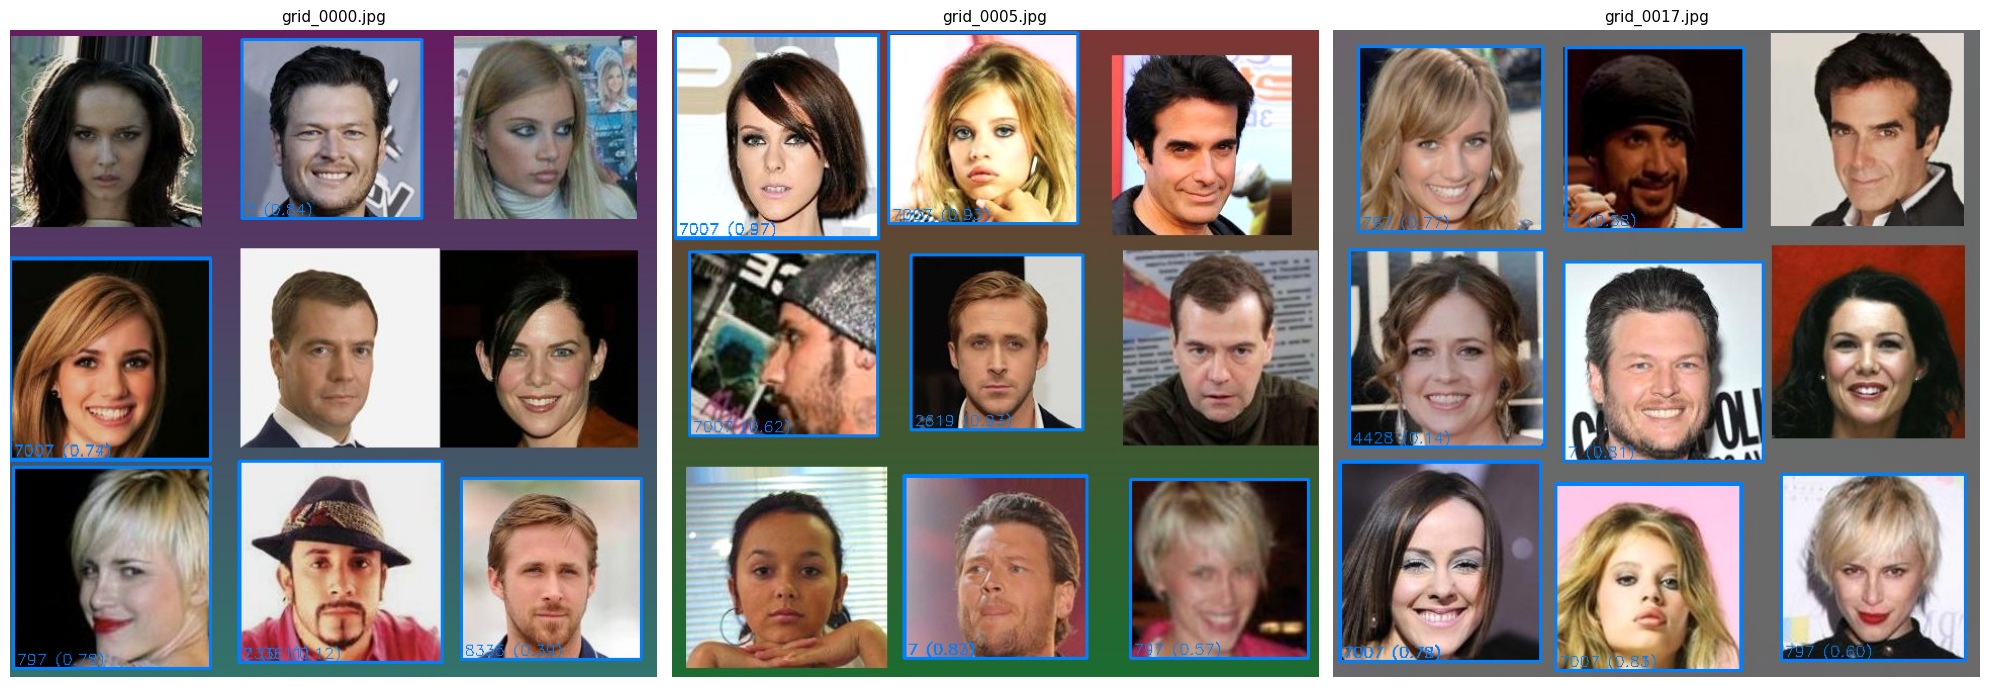

In [45]:
fig, axes = plt.subplots(1, min(3, len(all_results)), figsize=(20, 8))
if len(all_results) == 1: axes = [axes]
for ax, (f, res) in zip(axes, list(all_results.items())[:3]):
    img = cv2.imread(f)
    for r in res:
        x1, y1, x2, y2 = r["bbox"]
        color = (0, 255, 0) if r["source"] == "cls" else (255, 128, 0)
        cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
        text = f"{r['label']} ({r['confidence']:.2f})"
        if r["source"] == "cls":
            (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
            cv2.rectangle(img, (x1, y1 - th - 6), (x1 + tw, y1), color, -1)
            cv2.putText(img, text, (x1, y1 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,255,255), 1)
        else:
            cv2.putText(img, text, (x1 + 3, y2 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(os.path.basename(f), fontsize=11)
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(SCRIPT_DIR, "pipeline_summary.png"), dpi=150, bbox_inches="tight")
plt.show()


## Task 6: Results Gallery

In [46]:
gallery_dir = os.path.join(SCRIPT_DIR, "gallery")
n_correct = len(os.listdir(os.path.join(gallery_dir, "classification_correct")))
n_errors = len(os.listdir(os.path.join(gallery_dir, "classification_errors")))
n_det = len(os.listdir(os.path.join(gallery_dir, "detection")))
print(f"Gallery: {n_correct} correct + {n_errors} errors + {n_det} detection = {n_correct+n_errors+n_det} total")


Gallery: 25 correct + 6 errors + 11 detection = 42 total
